# Step 3: Exploratory analysis of UC San Diego works in OpenAlex

This notebook reads the tables made by `convert_export.py` (in `data/tables/`) and answers the workflow's step 3 questions with tables and charts.

**How to run**
1. Run `convert_export.py` first, so that `data/tables/` exists.
2. Open this notebook from the repo folder and choose **Run All**.
3. Charts are saved to `outputs/figures/` and summary tables to `outputs/tables/`. Those two folders are small and can be committed; `data/` cannot.

**Tables used** (all linked by `Work ID`): `works` (one row per work), `work_authors`, `work_countries`, `work_rors`, `work_institutions`, `work_funders`.

**Uncertainties** (change them in the settings cell below and rerun):
- Which types count as "journal articles" (default: `article` only).
- What "the last 5 years" means (both versions are shown).
- Where publisher information comes from (there is no publisher column; see the publishers section).

**Known limits of the data** (details in each section):
- The authors table has every author of a UCSD-affiliated work, not only UCSD authors, and it is missing the few works whose author columns didn't line up.
- Countries are not tied to individual authors.
- Citation counts are as of the date of the export.

In [ ]:
from pathlib import Path
from itertools import combinations
from collections import Counter

import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display

# ---------------------------------------------------------------------------
# Settings: change these if you want to customize the analysis
# ---------------------------------------------------------------------------
JOURNAL_ARTICLE_TYPES = ["article"]      # OpenAlex types counted as "journal articles" (add "review" if reviews should count)
BOOK_TYPES = ["book", "book-chapter"]    # types counted as "books" in the formats chart
LAST_YEAR_IS_PARTIAL = True              # the newest year in the data is not finished yet
UCSD_ROR = "https://ror.org/0168r3w48"   # UC San Diego's ROR ID (check it against the organizational identifier spreadsheet)
HOME_COUNTRY = "US"                      # left out of the "countries collaborated with" chart
TOP_N = 10                               # rows in the top-N tables
SOURCE_TABLE_TYPES = None                # None = all work types in the top journals table, or e.g. JOURNAL_ARTICLE_TYPES

# ---------------------------------------------------------------------------
# Find the tables made by convert_export.py
# ---------------------------------------------------------------------------
def find_tables_dir():
    here = Path.cwd()
    for base in [here, here.parent, here.parent.parent]:
        candidate = base / "data" / "tables"
        if (candidate / "works.csv").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find data/tables/works.csv. Run convert_export.py first, "
        "and open this notebook from the repo folder."
    )

TABLES_DIR = find_tables_dir()
OUTPUT_DIR = TABLES_DIR.parent.parent / "outputs"
FIG_DIR = OUTPUT_DIR / "figures"
TABLE_OUT_DIR = OUTPUT_DIR / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_OUT_DIR.mkdir(parents=True, exist_ok=True)
print("Reading tables from:", TABLES_DIR)

Reading tables from: /Users/aurora/Desktop/lib-research/lib-hdsi-2026-research-analytics/data/tables


## Helpers for tables and charts

Colors follow one validated palette: a single blue for single-series charts, and a fixed color per category when categories are compared, so a category keeps its color in every chart. Every chart has a table with the same numbers right above or below it, and the same table is saved to `outputs/tables/`.

In [2]:
# ---------------------------------------------------------------------------
# Palette and chart style
# ---------------------------------------------------------------------------
SURFACE = "#fcfcfb"   # chart background
INK = "#0b0b0b"       # titles
INK2 = "#52514e"      # secondary text, legends, value labels
MUTED = "#898781"     # axis labels
GRID = "#e1e0d9"      # gridlines (hairline, solid)
AXIS = "#c3c2b7"      # baseline
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]   # fixed order: blue, orange, aqua, yellow, magenta, green

mpl.rcParams["font.family"] = "sans-serif"
mpl.rcParams["axes.unicode_minus"] = False


def compact(value, pos=None):
    # Axis numbers: written out below 10,000 and shortened (10K, 1.5M) above
    if value >= 1_000_000:
        return f"{value / 1_000_000:g}M"
    if value >= 10_000:
        return f"{value / 1_000:g}K"
    return f"{value:,.0f}"


def shorten(text, n=42):
    return text if len(text) <= n else text[: n - 1] + "\u2026"


def style_ax(ax, grid_axis):
    ax.set_facecolor(SURFACE)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(AXIS)
    ax.tick_params(length=0, colors=MUTED, labelsize=9)
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)


def set_titles(ax, title, subtitle=""):
    ax.set_title(title, loc="left", fontsize=12, fontweight="bold", color=INK, pad=30)
    if subtitle:
        ax.text(0, 1.035, subtitle, transform=ax.transAxes, fontsize=9, color=INK2, va="bottom")


def new_fig(ncols=1, width=9.0, height=4.6):
    fig, axes = plt.subplots(1, ncols, figsize=(width, height))
    fig.patch.set_facecolor(SURFACE)
    return fig, axes


def draw_columns(ax, labels, values, number_format="{:,.0f}", compact_axis=True):
    # One series of columns, with the value written at the top of each column
    x = list(range(len(labels)))
    top = max(values) if len(values) else 1
    ax.bar(x, values, width=0.34, color=SERIES[0], zorder=3)
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_ylim(0, top * 1.14)
    for xi, v in zip(x, values):
        ax.text(xi, v + top * 0.015, number_format.format(v), ha="center", va="bottom", fontsize=9, color=INK2)
    if compact_axis:
        ax.yaxis.set_major_formatter(FuncFormatter(compact))
    style_ax(ax, "y")


def draw_hbars(ax, labels, values, number_format="{:,.0f}"):
    # One series of horizontal bars, largest at the top, with the value at the end of each bar
    y = list(range(len(labels)))[::-1]
    top = max(values) if len(values) else 1
    ax.barh(y, values, height=0.55, color=SERIES[0], zorder=3)
    ax.set_yticks(y)
    ax.set_yticklabels([shorten(str(label)) for label in labels])
    ax.set_xlim(0, top * 1.16)
    for yi, v in zip(y, values):
        ax.text(v + top * 0.012, yi, number_format.format(v), va="center", fontsize=9, color=INK2)
    ax.xaxis.set_major_formatter(FuncFormatter(compact))
    style_ax(ax, "x")


def draw_stacked(ax, table, colors, percent=False):
    # Stacked columns: rows of the table are the x positions, columns are the stacked categories
    x = list(range(len(table)))
    bottoms = [0] * len(table)
    for col in table.columns:
        vals = [float(v) for v in table[col].values]
        ax.bar(x, vals, bottom=bottoms, width=0.34, color=colors[col], edgecolor=SURFACE, linewidth=1.5, label=col, zorder=3)
        bottoms = [b + v for b, v in zip(bottoms, vals)]
    ax.set_xticks(x)
    ax.set_xticklabels([str(i) for i in table.index])
    if percent:
        ax.set_ylim(0, 100)
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
    else:
        ax.yaxis.set_major_formatter(FuncFormatter(compact))
    ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=len(table.columns),
              fontsize=9, labelcolor=INK2, handlelength=1, handleheight=1, columnspacing=1.6)
    style_ax(ax, "y")


def finish(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, facecolor=SURFACE, bbox_inches="tight")
    plt.show()


def save_table(df, name):
    df.to_csv(TABLE_OUT_DIR / f"{name}.csv", index=False)


def show(df):
    # Display a table with thousands separators (the saved CSV keeps plain numbers)
    out = df.copy()
    for col in out.columns:
        if col == "Year":
            continue
        if pd.api.types.is_integer_dtype(out[col]):
            out[col] = out[col].map(lambda v: "" if pd.isna(v) else f"{v:,}")
        elif pd.api.types.is_float_dtype(out[col]):
            out[col] = out[col].map(lambda v: "" if pd.isna(v) else f"{v:,.2f}")
    display(out.reset_index(drop=True))


COUNTRY_NAMES = {
    "US": "United States", "CN": "China", "GB": "United Kingdom", "DE": "Germany", "FR": "France", "CA": "Canada",
    "AU": "Australia", "JP": "Japan", "KR": "South Korea", "IT": "Italy", "ES": "Spain", "NL": "Netherlands",
    "CH": "Switzerland", "IN": "India", "BR": "Brazil", "SE": "Sweden", "DK": "Denmark", "NO": "Norway",
    "FI": "Finland", "BE": "Belgium", "AT": "Austria", "IL": "Israel", "SG": "Singapore", "HK": "Hong Kong",
    "TW": "Taiwan", "MX": "Mexico", "RU": "Russia", "PL": "Poland", "PT": "Portugal", "IE": "Ireland",
    "NZ": "New Zealand", "ZA": "South Africa", "AR": "Argentina", "CL": "Chile", "CO": "Colombia", "TR": "Turkey",
    "SA": "Saudi Arabia", "AE": "United Arab Emirates", "EG": "Egypt", "IR": "Iran", "GR": "Greece", "CZ": "Czechia",
    "HU": "Hungary", "TH": "Thailand", "MY": "Malaysia", "ID": "Indonesia", "VN": "Vietnam", "PK": "Pakistan",
    "NA": "Namibia", "NG": "Nigeria", "KE": "Kenya", "UA": "Ukraine", "RO": "Romania", "PR": "Puerto Rico",
}


def country_label(code):
    name = COUNTRY_NAMES.get(code)
    return f"{name} ({code})" if name else code

## Load the tables

Only an empty cell counts as blank when reading. (The text `NA` is a real country code, Namibia, and pandas would otherwise treat it as missing.)

In [3]:
def read_table(name, **kwargs):
    return pd.read_csv(TABLES_DIR / f"{name}.csv", keep_default_na=False, na_values=[""], **kwargs)


works = read_table("works", dtype={"Work ID": str, "DOI": str, "Source IDs": str})
works["Year"] = pd.to_numeric(works["Year"], errors="coerce").astype("Int64")
works["Citation count"] = pd.to_numeric(works["Citation count"], errors="coerce").fillna(0).astype(int)
works["Is paratext"] = works["Is paratext"].astype("boolean")
works["Retracted"] = works["Retracted"].astype("boolean")

authors = read_table("work_authors", dtype={"Work ID": str, "Author": str, "Author ID": str, "ORCID": str})
countries = read_table("work_countries", dtype={"Work ID": str, "Country": str})
rors = read_table("work_rors", dtype={"Work ID": str, "ROR ID": str})
funders = read_table("work_funders", dtype={"Work ID": str, "Funder": str, "Funder ID": str})

sizes = pd.DataFrame({
    "Table": ["works", "work_authors", "work_countries", "work_rors", "work_funders"],
    "Rows": [len(works), len(authors), len(countries), len(rors), len(funders)],
})
show(sizes)

,Table,Rows
0,works,"131,927"
1,work_authors,"1,649,609"
2,work_countries,"2,966,770"
3,work_rors,"2,677,515"
4,work_funders,"299,508"


## Overview

A first look at the data: how many works there are, the years covered, and the kinds of works. Paratext (covers, tables of contents) and retracted works are flagged in the data; they are **kept** in everything below, and counted here so you can see how many there are.

In [4]:
first_year = int(works["Year"].min())
last_year = int(works["Year"].max())
print(f"{len(works):,} works, {first_year} to {last_year}")
print(f"Paratext works: {int(works['Is paratext'].sum()):,}    Retracted works: {int(works['Retracted'].sum()):,}")

type_counts = works["Type"].value_counts().rename_axis("Type").rename("Works").reset_index()
show(type_counts)
save_table(type_counts, "works_by_type")

131,927 works, 2020 to 2026
Paratext works: 49    Retracted works: 29


,Type,Works
0,article,"69,080"
1,dataset,"20,530"
2,preprint,"7,919"
3,conference-paper,"7,115"
4,conference-abstract,"6,686"
5,review,"6,154"
6,other,"5,085"
7,book-chapter,"3,805"
8,editorial,"1,674"
9,erratum,869


## Question 1: How many works are there over the last 5 years?

"The last 5 years" can mean two things, so both are shown: the 5 most recent calendar years (the newest one is only partly finished), and the 5 most recent complete years.

,Definition,Works
0,All years in the data (2020-2026),"131,927"
1,"Last 5 calendar years (2022-2026, newest year ...","93,572"
2,Last 5 complete years (2021-2025),"90,126"


,Year,Works
0,2020,"20,354"
1,2021,"18,001"
2,2022,"17,443"
3,2023,"18,014"
4,2024,"18,165"
5,2025,"18,503"
6,2026,"21,447"


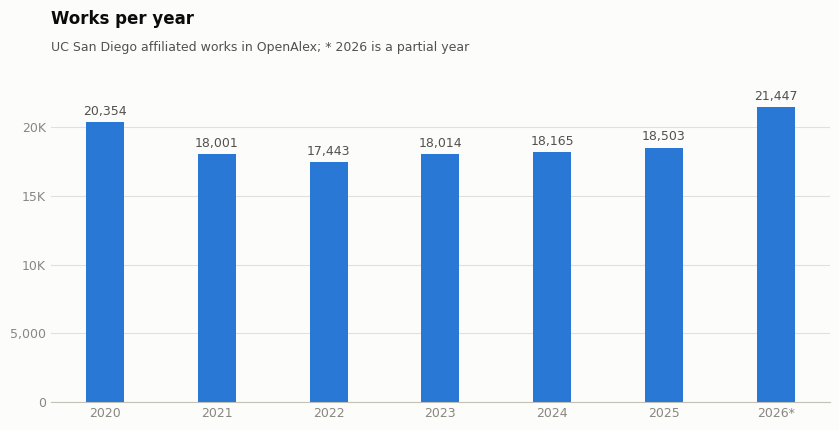

In [5]:
recent5 = list(range(last_year - 4, last_year + 1))
complete5 = list(range(last_year - 5, last_year)) if LAST_YEAR_IS_PARTIAL else recent5


def year_label(y):
    return f"{y}*" if (LAST_YEAR_IS_PARTIAL and y == last_year) else str(y)


q1 = pd.DataFrame({
    "Definition": [
        f"All years in the data ({first_year}-{last_year})",
        f"Last 5 calendar years ({recent5[0]}-{recent5[-1]}, newest year partial)" if LAST_YEAR_IS_PARTIAL else f"Last 5 years ({recent5[0]}-{recent5[-1]})",
        f"Last 5 complete years ({complete5[0]}-{complete5[-1]})",
    ],
    "Works": [len(works), int(works["Year"].isin(recent5).sum()), int(works["Year"].isin(complete5).sum())],
})
show(q1)
save_table(q1, "q1_total_works")

year_counts = works.groupby("Year").size().rename("Works").reset_index()
show(year_counts)
save_table(year_counts, "works_per_year")

fig, ax = new_fig(width=8.5, height=4.4)
draw_columns(ax, [year_label(int(y)) for y in year_counts["Year"]], list(year_counts["Works"]))
set_titles(ax, "Works per year", "UC San Diego affiliated works in OpenAlex" + (f"; * {last_year} is a partial year" if LAST_YEAR_IS_PARTIAL else ""))
finish(fig, "works_per_year")

## Question 2: How many unique UC San Diego researchers appear as authors?

**Read this first.** The export lists every author of each UCSD-affiliated work, including co-authors from other universities, and it does not say which author belongs to which institution. So counting unique author IDs gives the number of **unique authors on UCSD-affiliated works**, an upper bound on UCSD researchers, not the number of UCSD researchers itself. Getting the real number needs the faculty and staff directory match (the last item in the workflow).

Two more things affect the count:
- Authors without an OpenAlex author ID can't be counted as unique people. They are counted below.
- A few works were left out of the authors table because their author columns didn't line up in the export. They are listed in `misaligned_works.csv`.

In [6]:
authors_with_id = authors.dropna(subset=["Author ID"])
author_work = authors_with_id.merge(works[["Work ID", "Year"]], on="Work ID", how="inner")

q2 = pd.DataFrame({
    "Definition": q1["Definition"],
    "Unique authors on these works": [
        authors_with_id["Author ID"].nunique(),
        author_work.loc[author_work["Year"].isin(recent5), "Author ID"].nunique(),
        author_work.loc[author_work["Year"].isin(complete5), "Author ID"].nunique(),
    ],
})
show(q2)
save_table(q2, "q2_unique_authors")

unique_by_year = author_work.groupby("Year")["Author ID"].nunique().rename("Unique authors").reset_index()
show(unique_by_year)
save_table(unique_by_year, "unique_authors_per_year")

print(f"Author rows without an author ID (not counted above): {int(authors['Author ID'].isna().sum()):,} of {len(authors):,}")
print(f"Works with no rows in the authors table: {len(works) - authors['Work ID'].nunique():,} of {len(works):,}")

log_path = TABLES_DIR / "misaligned_works.csv"
if log_path.exists():
    log = pd.read_csv(log_path)
    print("\nWorks flagged when the tables were made:")
    show(log.groupby(["Table", "Outcome"]).size().rename("Works").reset_index())

,Definition,Unique authors on these works
0,All years in the data (2020-2026),"392,040"
1,"Last 5 calendar years (2022-2026, newest year ...","322,428"
2,Last 5 complete years (2021-2025),"292,257"


,Year,Unique authors
0,2020,"77,873"
1,2021,"85,633"
2,2022,"89,852"
3,2023,"86,774"
4,2024,"95,084"
5,2025,"99,283"
6,2026,"115,196"


Author rows without an author ID (not counted above): 74,336 of 1,649,609
Works with no rows in the authors table: 538 of 131,927

Works flagged when the tables were made:


,Table,Outcome,Works
0,work_authors,skipped,538
1,work_funders,kept IDs only,73
2,work_institutions,kept IDs only,"1,150"


**A rough measure of UCSD authorship.** The `work_rors` table has one entry per author affiliation. UCSD's ROR ID appears once for each author who lists UCSD, so counting those entries estimates how many author-work pairs involve UCSD. This counts entries, not unique people, and an author who lists two UCSD-related affiliations is counted twice.

In [7]:
ucsd_entries = rors[rors["ROR ID"] == UCSD_ROR]
print(f"UCSD ROR entries: {len(ucsd_entries):,}")
print(f"Works with at least one UCSD ROR entry: {ucsd_entries['Work ID'].nunique():,} of {len(works):,}")
print(f"Total author rows on all works: {len(authors):,}")

UCSD ROR entries: 327,969
Works with at least one UCSD ROR entry: 128,675 of 131,927
Total author rows on all works: 1,649,609


## Question 3: Citations to journal articles each year, and citations per unique author

For each publication year: the total citations to journal articles (the types set in `JOURNAL_ARTICLE_TYPES`), the number of unique authors of those articles, and citations divided by unique authors.

Citations are added up from the `works` table only, where each work appears once. (Adding them after joining to the authors table would count each work once for every author.) Citation counts are as of the export date, so recent years have had less time to be cited.

,Year,Journal articles,Total citations,Unique authors,Citations per author
0,2020,"10,179","616,088","63,034",9.77
1,2021,"10,089","439,842","70,163",6.27
2,2022,"9,807","344,653","72,935",4.73
3,2023,"9,548","242,137","67,619",3.58
4,2024,"9,966","180,811","75,136",2.41
5,2025,"10,454","93,441","77,413",1.21
6,2026,"9,037","20,633","81,932",0.25


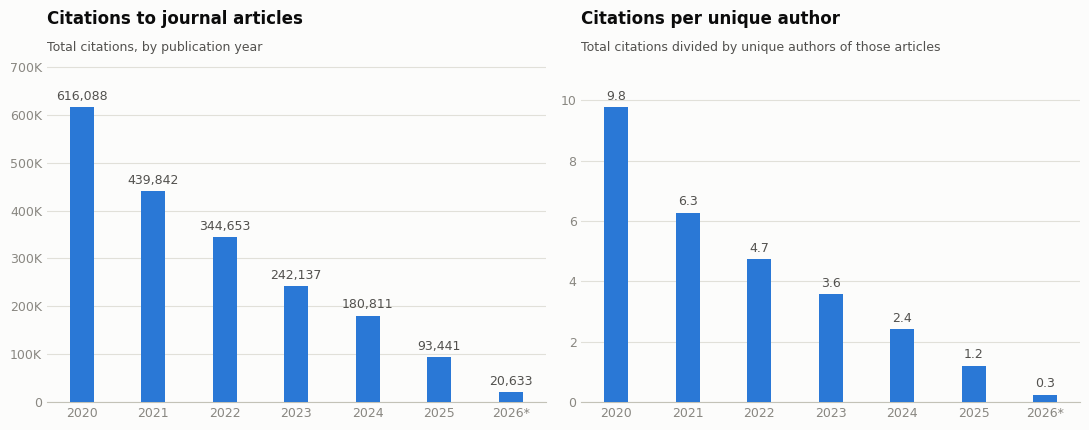

In [8]:
journal_articles = works[works["Type"].isin(JOURNAL_ARTICLE_TYPES)]

cites = journal_articles.groupby("Year").agg(**{
    "Journal articles": ("Work ID", "size"),
    "Total citations": ("Citation count", "sum"),
}).reset_index()

article_authors = authors_with_id.merge(journal_articles[["Work ID", "Year"]], on="Work ID", how="inner")
authors_by_year = article_authors.groupby("Year")["Author ID"].nunique().rename("Unique authors").reset_index()

q3 = cites.merge(authors_by_year, on="Year", how="left")
q3["Citations per author"] = q3["Total citations"] / q3["Unique authors"]
show(q3)
save_table(q3, "q3_citations_per_year")

labels = [year_label(int(y)) for y in q3["Year"]]
fig, (ax1, ax2) = new_fig(ncols=2, width=11, height=4.4)
draw_columns(ax1, labels, list(q3["Total citations"]))
set_titles(ax1, "Citations to journal articles", "Total citations, by publication year")
draw_columns(ax2, labels, list(q3["Citations per author"]), number_format="{:,.1f}", compact_axis=False)
set_titles(ax2, "Citations per unique author", "Total citations divided by unique authors of those articles")
finish(fig, "citations_per_year")

## Top 10 publishers, with their top 5 journals

**The export has no publisher column**, only the journal (`Source`). So the top journals are shown first. The publisher table needs a lookup from source ID to publisher: save it as `data/publisher_lookup.csv` with the columns `Source IDs` and `Publisher` (IDs written either as `S123456` or as the full OpenAlex link). If the file is there, the publisher table is built; if not, this section says so.

Sources include repositories (for example data repositories) as well as journals. Set `SOURCE_TABLE_TYPES` in the settings if only certain work types should be counted.

Works with a source: 130,539 of 131,927


,Source,Source IDs,Works
0,UC San Diego,S7407050887,"17,152"
1,arXiv (Cornell University),S4306400194,"3,549"
2,The Human BioMolecular Atlas Program (HuBMAP),S7407052399,"3,271"
3,bioRxiv (Cold Spring Harbor Laboratory),S4306402567,"1,337"
4,Cambridge University Press eBooks,S4306462995,"1,217"
5,Zenodo (CERN European Organization for Nuclear...,S4306400562,"1,206"
6,OSTI OAI (U.S. Department of Energy Office of ...,S4306402487,"1,202"
7,Springer eBooks,S4306463937,"1,180"
8,Nature Communications,S64187185,"1,091"
9,DOE Pacific Northwest National Laboratory (PNN...,S7407051155,"1,054"


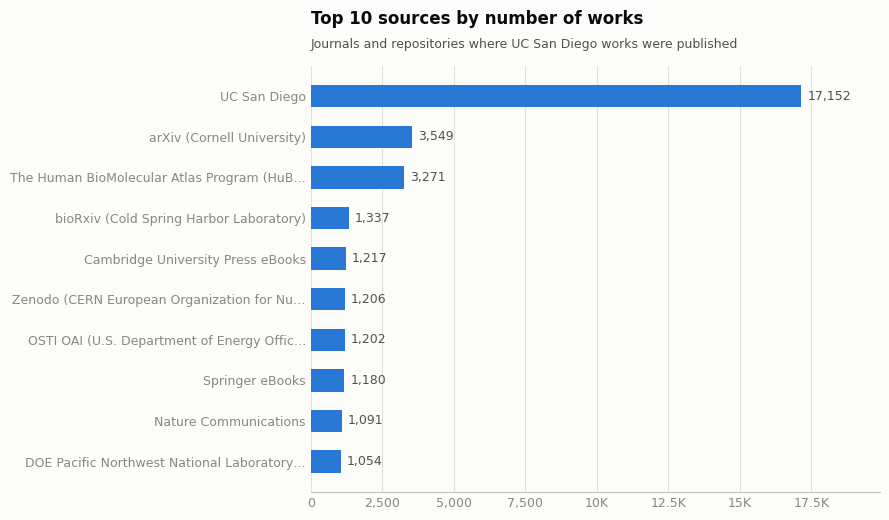

In [9]:
src = works.dropna(subset=["Source IDs"])
if SOURCE_TABLE_TYPES is not None:
    src = src[src["Type"].isin(SOURCE_TABLE_TYPES)]

source_counts = (
    src.groupby("Source IDs")
    .agg(Source=("Source", "first"), Works=("Work ID", "size"))
    .sort_values("Works", ascending=False)
    .reset_index()
)
top_sources = source_counts.head(TOP_N)[["Source", "Source IDs", "Works"]]
print(f"Works with a source: {len(src):,} of {len(works):,}")
show(top_sources)
save_table(top_sources, "top_sources")

fig, ax = new_fig(width=9, height=0.34 * len(top_sources) + 1.9)
draw_hbars(ax, list(top_sources["Source"]), list(top_sources["Works"]))
set_titles(ax, f"Top {len(top_sources)} sources by number of works", "Journals and repositories where UC San Diego works were published")
finish(fig, "top_sources")

In [10]:
lookup_path = TABLES_DIR.parent / "publisher_lookup.csv"

if not lookup_path.exists():
    print("No publisher lookup found at", lookup_path)
    print("Add a file with the columns 'Source IDs' and 'Publisher' to build the publisher table.")
else:
    lookup = pd.read_csv(lookup_path, dtype=str)
    if not {"Source IDs", "Publisher"}.issubset(lookup.columns):
        print("publisher_lookup.csv needs the columns 'Source IDs' and 'Publisher'. Found:", list(lookup.columns))
    else:
        lookup["Source IDs"] = lookup["Source IDs"].str.strip().str.split("/").str[-1]
        lookup = lookup.dropna(subset=["Publisher"]).drop_duplicates("Source IDs")
        with_pub = src.merge(lookup[["Source IDs", "Publisher"]], on="Source IDs", how="left")
        print(f"Works whose source has a publisher in the lookup: {with_pub['Publisher'].notna().sum():,} of {len(with_pub):,}")

        pub_counts = with_pub.dropna(subset=["Publisher"]).groupby("Publisher").size().sort_values(ascending=False)
        rows = []
        for publisher, n in pub_counts.head(TOP_N).items():
            top_journals = (
                with_pub[with_pub["Publisher"] == publisher]
                .groupby("Source IDs")
                .agg(Source=("Source", "first"), Works=("Work ID", "size"))
                .sort_values("Works", ascending=False)
                .head(5)
            )
            rows.append({
                "Publisher": publisher,
                "Works": n,
                "Top 5 journals (works)": "; ".join(f"{r.Source} ({r.Works:,})" for r in top_journals.itertuples()),
            })
        top_publishers = pd.DataFrame(rows)
        pd.set_option("display.max_colwidth", 200)
        show(top_publishers)
        save_table(top_publishers, "top_publishers")

No publisher lookup found at /Users/aurora/Desktop/lib-research/lib-hdsi-2026-research-analytics/data/publisher_lookup.csv
Add a file with the columns 'Source IDs' and 'Publisher' to build the publisher table.


## Top 10 funders, with their top 5 research domains

Each funder is counted once per work. A work with several funders counts for each of them, and a work with no funder listed is not counted here. For the domains, each work's single `Domain` from the works table is used. Some works were exported with funder IDs but no names; the names are filled in from other works with the same ID.

In [11]:
funders = funders.dropna(subset=["Funder ID"])
funder_names = funders.dropna(subset=["Funder"]).drop_duplicates("Funder ID").set_index("Funder ID")["Funder"]

funder_works = funders.drop_duplicates(["Work ID", "Funder ID"])
print(f"Works with at least one funder: {funder_works['Work ID'].nunique():,} of {len(works):,} "
      f"({funder_works['Work ID'].nunique() / len(works):.0%})")

top_funder_ids = funder_works.groupby("Funder ID").size().sort_values(ascending=False).head(TOP_N)

with_domain = funder_works.merge(works[["Work ID", "Domain"]], on="Work ID", how="left").dropna(subset=["Domain"])
domain_counts = with_domain.groupby(["Funder ID", "Domain"]).size().rename("Works").reset_index()
domain_counts = domain_counts[domain_counts["Funder ID"].isin(top_funder_ids.index)]
domain_counts = domain_counts.sort_values(["Funder ID", "Works"], ascending=[True, False]).groupby("Funder ID").head(5)
domain_text = (
    domain_counts.assign(text=domain_counts["Domain"] + " (" + domain_counts["Works"].map("{:,}".format) + ")")
    .groupby("Funder ID")["text"].apply("; ".join)
)

top_funders = pd.DataFrame({
    "Funder": [funder_names.get(i, i) for i in top_funder_ids.index],
    "Funder ID": list(top_funder_ids.index),
    "Works": list(top_funder_ids.values),
    "Top 5 domains (works)": [domain_text.get(i, "") for i in top_funder_ids.index],
})
pd.set_option("display.max_colwidth", 200)
show(top_funders)
save_table(top_funders, "top_funders")
save_table(domain_counts.assign(Funder=domain_counts["Funder ID"].map(funder_names)), "funder_domains")

Works with at least one funder: 58,862 of 131,927 (45%)


,Funder,Funder ID,Works,Top 5 domains (works)
0,National Institutes of Health,F4320332161,"19,656","Health Sciences (9,710); Life Sciences (7,362); Physical Sciences (1,365); Social Sciences (1,214)"
1,National Science Foundation,F4320306076,"12,581","Physical Sciences (9,109); Life Sciences (2,163); Social Sciences (729); Health Sciences (555)"
2,"University of California, San Diego",F4320332603,"7,361","Health Sciences (2,371); Life Sciences (2,248); Physical Sciences (2,058); Social Sciences (680)"
3,National Cancer Institute,F4320337351,"5,653","Health Sciences (2,799); Life Sciences (2,325); Physical Sciences (370); Social Sciences (159)"
4,National Institute of General Medical Sciences,F4320337354,"5,496","Life Sciences (3,470); Health Sciences (1,400); Physical Sciences (475); Social Sciences (150)"
5,"National Heart, Lung, and Blood Institute",F4320337338,"5,172","Health Sciences (3,381); Life Sciences (1,294); Social Sciences (264); Physical Sciences (230)"
6,National Institute of Allergy and Infectious Diseases,F4320337355,"4,449","Health Sciences (2,392); Life Sciences (1,753); Physical Sciences (183); Social Sciences (120)"
7,National Institute of Diabetes and Digestive and Kidney Diseases,F4320337357,"4,257","Health Sciences (2,702); Life Sciences (1,285); Social Sciences (177); Physical Sciences (91)"
8,National Institute on Aging,F4320337337,"4,212","Health Sciences (2,278); Life Sciences (1,438); Social Sciences (287); Physical Sciences (208)"
9,National Institute of Mental Health,F4320337346,"4,154","Life Sciences (1,678); Health Sciences (1,487); Social Sciences (851); Physical Sciences (138)"


## Chart: journal articles, books, and other formats each year

Works are grouped into three formats using the type lists in the settings: journal articles, books and book chapters, and everything else (datasets, preprints, conference papers, and so on). Books are a very small share, so read the table for their exact numbers.

Format,Year,Journal article,Book or book chapter,Other
0,2020,"10,179",676,"9,499"
1,2021,"10,089",526,"7,386"
2,2022,"9,807",732,"6,904"
3,2023,"9,548",668,"7,798"
4,2024,"9,966",722,"7,477"
5,2025,"10,454",391,"7,658"
6,2026*,"9,037",339,"12,071"


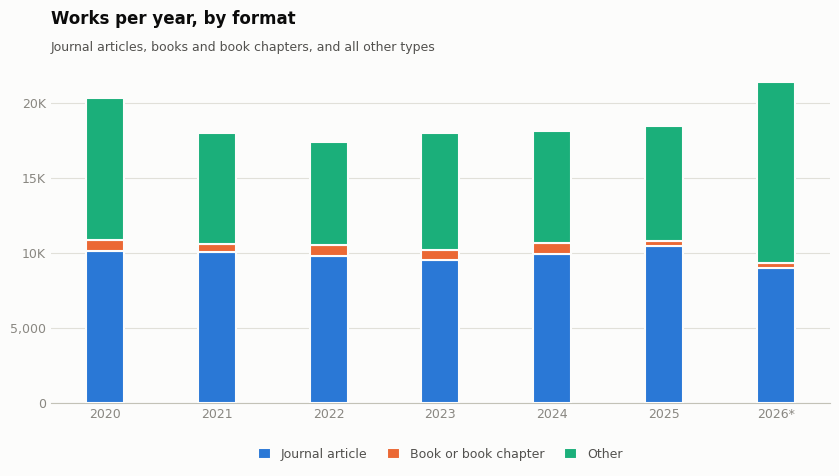

In [12]:
def format_group(t):
    if t in JOURNAL_ARTICLE_TYPES:
        return "Journal article"
    if t in BOOK_TYPES:
        return "Book or book chapter"
    return "Other"


FORMAT_ORDER = ["Journal article", "Book or book chapter", "Other"]
FORMAT_COLORS = dict(zip(FORMAT_ORDER, SERIES[:3]))

formats = works.assign(Format=works["Type"].map(format_group))
formats_by_year = formats.groupby(["Year", "Format"]).size().unstack("Format", fill_value=0).reindex(columns=FORMAT_ORDER, fill_value=0)
formats_by_year.index = [year_label(int(y)) for y in formats_by_year.index]

show(formats_by_year.rename_axis("Year").reset_index())
save_table(formats_by_year.rename_axis("Year").reset_index(), "formats_per_year")

fig, ax = new_fig(width=8.5, height=4.9)
draw_stacked(ax, formats_by_year, FORMAT_COLORS)
set_titles(ax, "Works per year, by format", "Journal articles, books and book chapters, and all other types")
finish(fig, "formats_per_year")

## Chart: open access status

`Open Access status` says how a work is open: gold (open in its journal), diamond (open in its journal with no author fees), green (open in a repository), hybrid (open in a subscription journal), bronze (free to read without a clear license), or closed. The first chart ranks the statuses over all works; the second shows each year's share.

,Open access status,Works,Share
0,green,"47,856",36.30
1,closed,"29,951",22.70
2,gold,"22,674",17.20
3,hybrid,"16,493",12.50
4,bronze,"11,124",8.40
5,diamond,"3,829",2.90


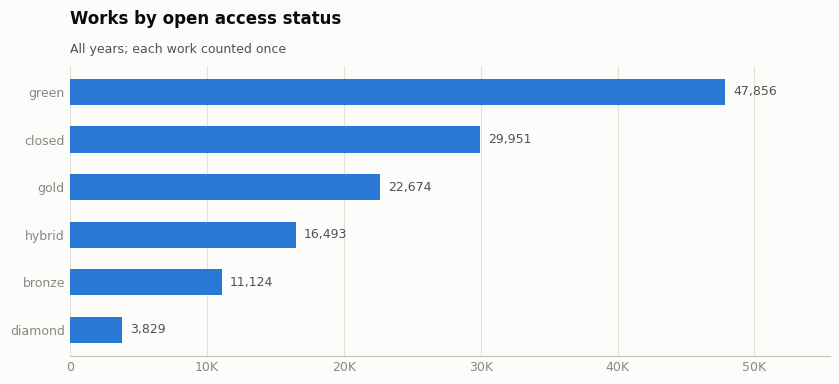

OA,Year,diamond,gold,green,hybrid,bronze,closed
0,2020,2.60,13.00,43.10,6.00,10.50,24.90
1,2021,2.70,17.60,36.30,9.00,9.90,24.60
2,2022,2.90,18.90,32.40,11.80,9.30,24.80
3,2023,3.40,18.00,29.10,13.60,12.10,23.80
4,2024,3.50,18.80,30.70,16.00,8.80,22.20
5,2025,3.10,20.10,30.80,18.00,6.60,21.40
6,2026*,2.30,14.80,48.50,13.60,2.70,18.00


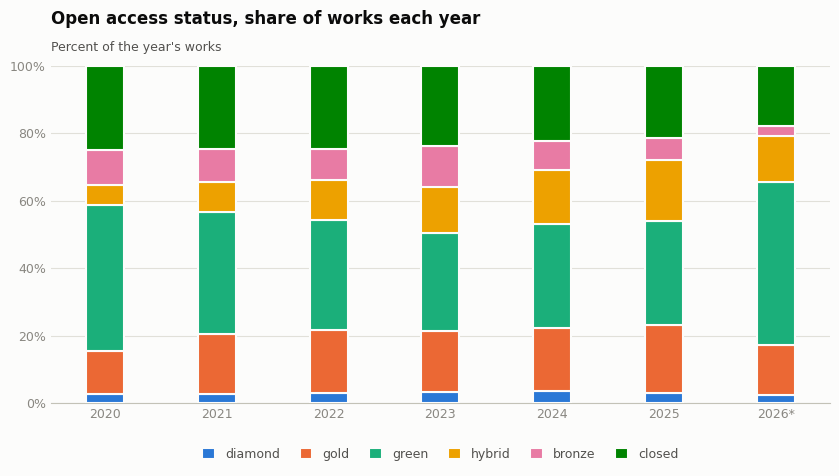

In [13]:
OA_ORDER = ["diamond", "gold", "green", "hybrid", "bronze", "closed"]
OA_COLORS = dict(zip(OA_ORDER, SERIES))
OA_COLORS["other / unknown"] = MUTED


def oa_group(status):
    status = "unknown" if pd.isna(status) else str(status).strip().lower()
    return status if status in OA_ORDER else "other / unknown"


oa = works.assign(OA=works["Open Access status"].map(oa_group))
oa_overall = oa["OA"].value_counts().rename_axis("Open access status").rename("Works").reset_index()
oa_overall["Share"] = (oa_overall["Works"] / oa_overall["Works"].sum() * 100).round(1)
show(oa_overall)
save_table(oa_overall, "open_access_overall")

fig, ax = new_fig(width=8.5, height=0.34 * len(oa_overall) + 1.9)
draw_hbars(ax, list(oa_overall["Open access status"]), list(oa_overall["Works"]))
set_titles(ax, "Works by open access status", "All years; each work counted once")
finish(fig, "open_access_overall")

oa_year = oa.groupby(["Year", "OA"]).size().unstack("OA", fill_value=0)
oa_year = oa_year.reindex(columns=[c for c in OA_ORDER + ["other / unknown"] if c in oa_year.columns], fill_value=0)
oa_share = oa_year.div(oa_year.sum(axis=1), axis=0) * 100
oa_share.index = [year_label(int(y)) for y in oa_share.index]

table = oa_share.round(1).rename_axis("Year").reset_index()
show(table)
save_table(table, "open_access_share_per_year")

fig, ax = new_fig(width=8.5, height=4.9)
draw_stacked(ax, oa_share, OA_COLORS, percent=True)
set_titles(ax, "Open access status, share of works each year", "Percent of the year's works")
finish(fig, "open_access_per_year")

## Chart: which countries do UC San Diego authors collaborate with?

Each country is counted once per work: the number of works with at least one author affiliation in that country. The export does not say which author each country belongs to, so this shows which countries appear **on the same works as UCSD**, not which author collaborated with whom. The home country is left out of the chart (it is in nearly every work).

For a network, the table of country pairs lists which countries appear together on works. The full list of pairs is saved to `outputs/tables/country_pairs.csv` and can be loaded into a network tool.

Works with at least one country: 131,927 of 131,927


,Country,Works
0,United Kingdom (GB),"10,382"
1,Canada (CA),"10,051"
2,Germany (DE),"8,568"
3,China (CN),"8,486"
4,France (FR),"6,685"
5,Australia (AU),"6,625"
6,Italy (IT),"5,422"
7,Switzerland (CH),"4,737"
8,Japan (JP),"4,722"
9,Spain (ES),"4,278"


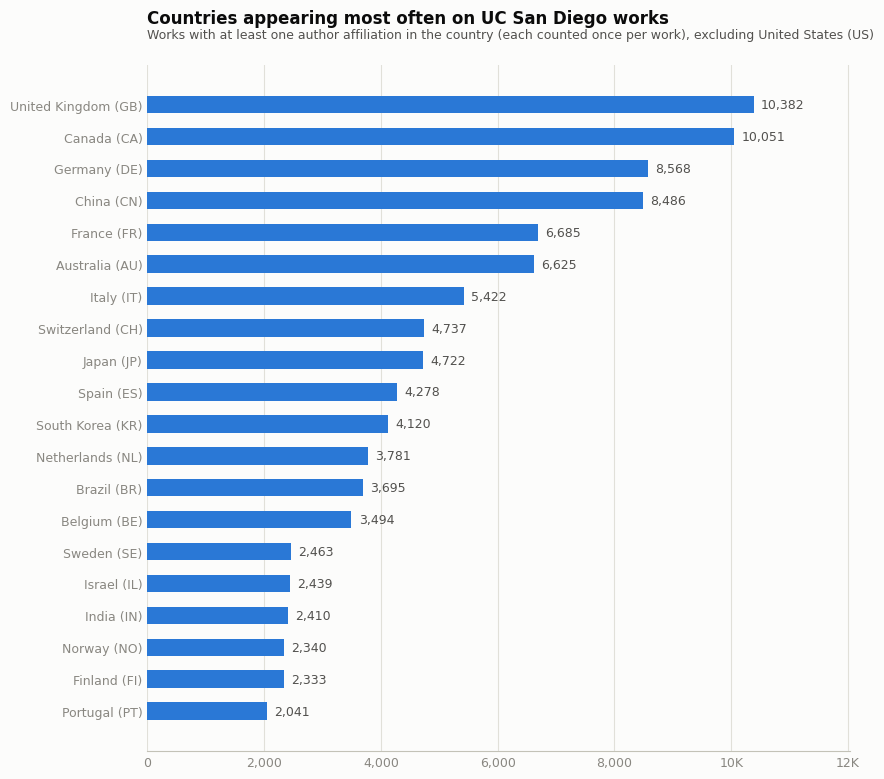

In [14]:
countries_by_work = countries.dropna(subset=["Country"]).drop_duplicates(["Work ID", "Country"])
print(f"Works with at least one country: {countries_by_work['Work ID'].nunique():,} of {len(works):,}")

country_counts = countries_by_work.groupby("Country").size().sort_values(ascending=False)
partners = country_counts.drop(HOME_COUNTRY, errors="ignore").head(20)

partner_table = pd.DataFrame({
    "Country": [country_label(c) for c in partners.index],
    "Works": list(partners.values),
})
show(partner_table)
save_table(partner_table, "countries_top")

fig, ax = new_fig(width=9, height=0.3 * len(partners) + 1.9)
draw_hbars(ax, list(partner_table["Country"]), list(partner_table["Works"]))
set_titles(ax, "Countries appearing most often on UC San Diego works",
           f"Works with at least one author affiliation in the country (each counted once per work), excluding {country_label(HOME_COUNTRY)}")
finish(fig, "countries_top")

In [ ]:
# Pairs of countries that appear together on the same work
per_work = countries_by_work.sort_values("Country").groupby("Work ID")["Country"].agg(list)

pair_counts = Counter()
for country_list in per_work:
    if len(country_list) > 1:
        pair_counts.update(combinations(country_list, 2))

pairs = pd.DataFrame(
    [(country_label(a), country_label(b), a, b, n) for (a, b), n in pair_counts.items()],
    columns=["Country A", "Country B", "Code A", "Code B", "Works"],
).sort_values("Works", ascending=False)

print("Top pairs of countries on the same work:")
show(pairs.head(15)[["Country A", "Country B", "Works"]])

without_home = pairs[(pairs["Code A"] != HOME_COUNTRY) & (pairs["Code B"] != HOME_COUNTRY)]
print(f"Top pairs not involving {country_label(HOME_COUNTRY)}:")
show(without_home.head(15)[["Country A", "Country B", "Works"]])

save_table(pairs.head(500)[["Code A", "Code B", "Country A", "Country B", "Works"]], "country_pairs")

## Still to do: OpenAlex IDs for all UC San Diego affiliates

This part uses the faculty and staff directory, which is restricted to UCSD. **Do not put that file, or anything made from it that names people, in the repo.** Keep the directory and the results in the shared Google folder or an ignored folder such as `data/`.

Suggested approach (to agree on with the team):
1. Normalize names in the directory and in the `Author` column (case, accents, punctuation, middle initials).
2. **Certain** match: the directory has an ORCID that equals an author's ORCID in `work_authors`, or exactly one author matches the full name and UCSD is among that author's affiliations.
3. **Uncertain** match: the name matches but several authors share it, or the name is only a partial match. Keep all candidates and flag them for review.
4. Report how many people have no match.

This also answers the earlier question about **unique UCSD researchers**: once directory members are linked to author IDs, count those IDs in `work_authors`.

In [15]:
# Everything this notebook saved
for folder in (FIG_DIR, TABLE_OUT_DIR):
    print(folder.relative_to(OUTPUT_DIR.parent))
    for f in sorted(folder.glob("*")):
        print("   ", f.name)

outputs/figures
    citations_per_year.png
    countries_top.png
    formats_per_year.png
    open_access_overall.png
    open_access_per_year.png
    top_sources.png
    works_per_year.png
outputs/tables
    countries_top.csv
    formats_per_year.csv
    funder_domains.csv
    open_access_overall.csv
    open_access_share_per_year.csv
    q1_total_works.csv
    q2_unique_authors.csv
    q3_citations_per_year.csv
    top_funders.csv
    top_sources.csv
    unique_authors_per_year.csv
    works_by_type.csv
    works_per_year.csv
